<a href="https://colab.research.google.com/github/shiyamtmlzs-cell/iba-smart-chatbot/blob/main/Household_Energy_Consumption_CA4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_excel(
    "/content/household_energy_consumption.xlsx"
)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (90000, 7)


,Household_ID,Date,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Has_AC,Peak_Hours_Usage_kWh
0,H00001,2025-04-01,8.4,4,17.8,No,3.2
1,H00001,2025-04-02,7.9,4,17.3,No,2.8
2,H00001,2025-04-03,9.2,4,18.6,No,3.0
3,H00001,2025-04-04,7.9,4,18.2,No,2.7
4,H00001,2025-04-05,9.6,4,11.9,No,3.2


In [3]:
# Check column names
print("Columns:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
print("\nStatistical summary:")
display(df.describe())

Columns:
['Household_ID', 'Date', 'Energy_Consumption_kWh', 'Household_Size', 'Avg_Temperature_C', 'Has_AC', 'Peak_Hours_Usage_kWh']

Data types:
Household_ID                      object
Date                      datetime64[ns]
Energy_Consumption_kWh           float64
Household_Size                     int64
Avg_Temperature_C                float64
Has_AC                            object
Peak_Hours_Usage_kWh             float64
dtype: object

Missing values:
Household_ID              0
Date                      0
Energy_Consumption_kWh    0
Household_Size            0
Avg_Temperature_C         0
Has_AC                    0
Peak_Hours_Usage_kWh      0
dtype: int64

Duplicate rows: 0

Statistical summary:


,Date,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Peak_Hours_Usage_kWh
count,90000,90000.000000,90000.000000,90000.000000,90000.000000
mean,2025-04-04 00:00:03.840000256,10.571988,3.487811,17.505802,4.319557
min,2025-04-01 00:00:00,0.500000,1.000000,10.000000,0.200000
25%,2025-04-02 00:00:00,6.000000,2.000000,15.800000,2.300000
50%,2025-04-04 00:00:00,10.400000,3.000000,17.500000,4.000000
75%,2025-04-06 00:00:00,14.800000,5.000000,19.200000,6.000000
max,2025-04-08 00:00:00,20.000000,6.000000,25.000000,10.000000
std,NaN,5.519494,1.709761,2.491621,2.531432


In [4]:
# Convert Date to the correct format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert numeric columns
numeric_columns = [
    "Energy_Consumption_kWh",
    "Household_Size",
    "Avg_Temperature_C",
    "Peak_Hours_Usage_kWh"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows with missing required values
df = df.dropna().copy()

# Remove exact duplicate records
df = df.drop_duplicates().copy()

# Remove invalid negative energy values
df = df[
    (df["Energy_Consumption_kWh"] >= 0) &
    (df["Peak_Hours_Usage_kWh"] >= 0) &
    (df["Household_Size"] > 0)
].copy()

print("Data cleaning completed!")
print("Final dataset size:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())

display(df.head())

Data cleaning completed!
Final dataset size: (90000, 7)
Missing values remaining: 0


,Household_ID,Date,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Has_AC,Peak_Hours_Usage_kWh
0,H00001,2025-04-01,8.4,4,17.8,No,3.2
1,H00001,2025-04-02,7.9,4,17.3,No,2.8
2,H00001,2025-04-03,9.2,4,18.6,No,3.0
3,H00001,2025-04-04,7.9,4,18.2,No,2.7
4,H00001,2025-04-05,9.6,4,11.9,No,3.2


In [5]:
total_energy = df["Energy_Consumption_kWh"].sum()

average_energy = df["Energy_Consumption_kWh"].mean()

average_peak_usage = df["Peak_Hours_Usage_kWh"].mean()

average_temperature = df["Avg_Temperature_C"].mean()

total_households = df["Household_ID"].nunique()

print("Total Energy Consumption:", round(total_energy, 2), "kWh")
print("Average Energy Consumption:", round(average_energy, 2), "kWh")
print("Average Peak-Hour Usage:", round(average_peak_usage, 2), "kWh")
print("Average Temperature:", round(average_temperature, 2), "°C")
print("Unique Households:", total_households)

Total Energy Consumption: 951478.9 kWh
Average Energy Consumption: 10.57 kWh
Average Peak-Hour Usage: 4.32 kWh
Average Temperature: 17.51 °C
Unique Households: 12857


In [6]:
ac_analysis = df.groupby("Has_AC")[
    "Energy_Consumption_kWh"
].agg(["count", "mean", "median"])

display(ac_analysis.round(2))

,count,mean,median
Has_AC,,,
No,45508,8.68,8.6
Yes,44492,12.51,12.9


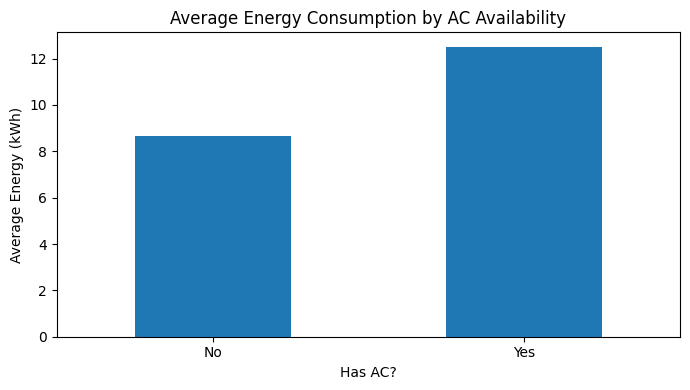

In [7]:
ac_analysis["mean"].plot(
    kind="bar",
    figsize=(7, 4),
    title="Average Energy Consumption by AC Availability",
    ylabel="Average Energy (kWh)",
    xlabel="Has AC?"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
size_analysis = df.groupby("Household_Size")[
    "Energy_Consumption_kWh"
].mean()

display(size_analysis.round(2))

,Energy_Consumption_kWh
Household_Size,
1,3.29
2,6.23
3,9.18
4,12.25
5,15.22
6,17.47


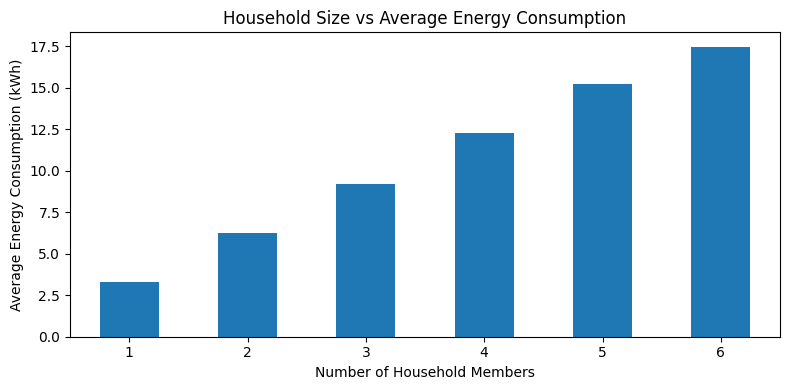

In [9]:
size_analysis.plot(
    kind="bar",
    figsize=(8, 4),
    title="Household Size vs Average Energy Consumption",
    xlabel="Number of Household Members",
    ylabel="Average Energy Consumption (kWh)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

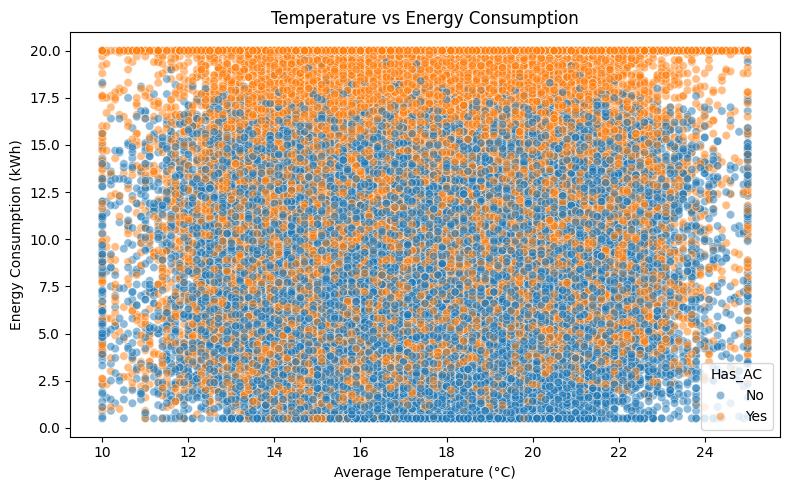

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Avg_Temperature_C",
    y="Energy_Consumption_kWh",
    hue="Has_AC",
    alpha=0.5
)

plt.title("Temperature vs Energy Consumption")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Energy Consumption (kWh)")

plt.tight_layout()
plt.show()

,Energy_Consumption_kWh
Date,
2025-04-01,135998.9
2025-04-02,135977.1
2025-04-03,135854.1
2025-04-04,136034.0
2025-04-05,135924.1
2025-04-06,135723.0
2025-04-07,135960.5
2025-04-08,7.2


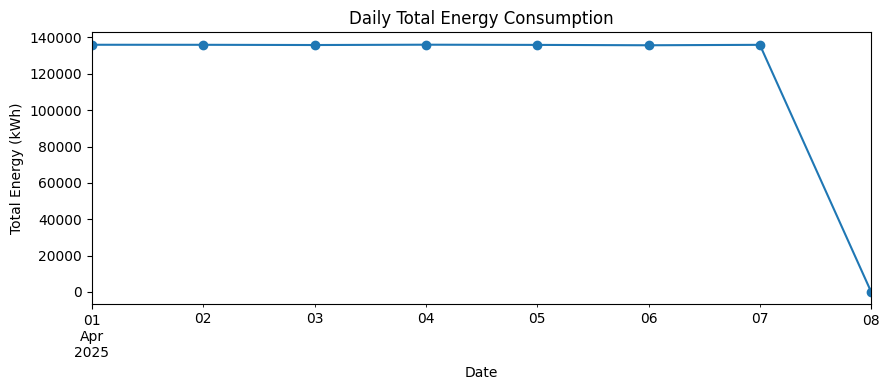

In [11]:
daily_energy = df.groupby("Date")[
    "Energy_Consumption_kWh"
].sum()

display(daily_energy)

daily_energy.plot(
    kind="line",
    marker="o",
    figsize=(9, 4),
    title="Daily Total Energy Consumption",
    xlabel="Date",
    ylabel="Total Energy (kWh)"
)

plt.tight_layout()
plt.show()

In [12]:
print(df.groupby("Date").size())

Date
2025-04-01    12857
2025-04-02    12857
2025-04-03    12857
2025-04-04    12857
2025-04-05    12857
2025-04-06    12857
2025-04-07    12857
2025-04-08        1
dtype: int64


,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Peak_Hours_Usage_kWh
Energy_Consumption_kWh,1.00,0.89,0.03,0.97
Household_Size,0.89,1.00,0.00,0.79
Avg_Temperature_C,0.03,0.00,1.00,0.03
Peak_Hours_Usage_kWh,0.97,0.79,0.03,1.00


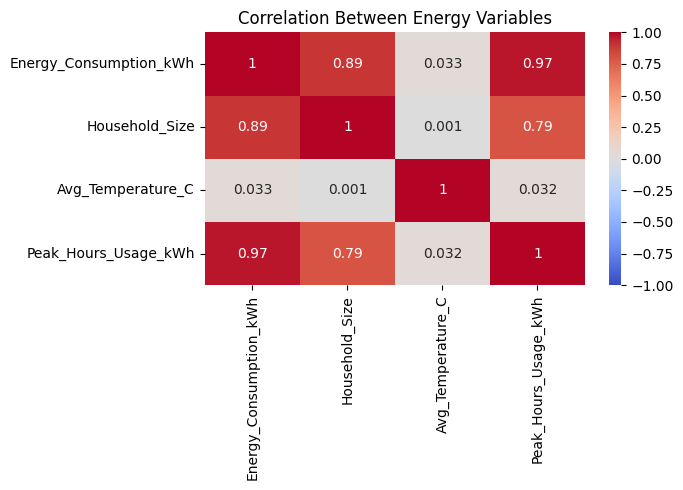

In [13]:
correlation = df[
    [
        "Energy_Consumption_kWh",
        "Household_Size",
        "Avg_Temperature_C",
        "Peak_Hours_Usage_kWh"
    ]
].corr()

display(correlation.round(2))

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Energy Variables")
plt.tight_layout()
plt.show()

In [14]:
peak_total = df["Peak_Hours_Usage_kWh"].sum()

peak_percentage = (
    peak_total / total_energy * 100
    if total_energy > 0 else 0
)

print("Total Peak-Hour Usage:", round(peak_total, 2), "kWh")
print("Peak-Hour Usage as % of Total Energy:",
      round(peak_percentage, 2), "%")

Total Peak-Hour Usage: 388760.1 kWh
Peak-Hour Usage as % of Total Energy: 40.86 %
